<a href="https://colab.research.google.com/github/Pulakspbl/project_GCI/blob/main/project_forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, gdown;
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
path = gdown.download(id="1ETlCkVovz68-OZgoSYs6fTQ1OfLLnNCI", output="territory_sales.xlsx", quiet=True, fuzzy=True)

In [2]:
df_q = pd.read_excel("territory_sales.xlsx", sheet_name="sls_q")
df_v = pd.read_excel("territory_sales.xlsx", sheet_name="sls_v")

In [3]:
print("df_q:", df_q.shape)
print("df_v:", df_v.shape)

df_q: (11886, 69)
df_v: (11886, 69)


In [4]:
df_q.head()

,HQ-Name,DIVISION,BRAND,Therapy,2020-04-01 00:00:00,2020-05-01 00:00:00,2020-06-01 00:00:00,2020-07-01 00:00:00,2020-08-01 00:00:00,2020-09-01 00:00:00,...,2024-07-01 00:00:00,2024-08-01 00:00:00,2024-09-01 00:00:00,2024-10-01 00:00:00,2024-11-01 00:00:00,2024-12-01 00:00:00,2025-01-01 00:00:00,2025-02-01 00:00:00,2025-03-01 00:00:00,Sales Qty 24-25
0,CHANDONA-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,125.0,107.0,144.0,151.5,144.0,194.5,...,310.9,289.000000,390.0,272.633333,283.80,235.0,165.835,234.1,227.0,3313.268333
1,RAJBARI MOOR-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,125.0,107.0,144.0,151.5,144.0,194.5,...,310.9,289.000000,390.0,272.633333,283.80,235.0,165.835,234.1,227.0,3313.268333
2,TONGI-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,164.0,124.0,169.0,146.0,138.0,161.0,...,269.8,244.200000,264.0,294.000000,272.00,313.6,263.330,338.2,308.0,3270.330000
3,KAPASIA-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,46.0,35.0,42.0,44.0,64.0,88.0,...,198.0,197.000000,273.0,189.000000,204.00,233.0,188.000,170.0,198.0,2345.000000
4,MAWNA-AVIOR,AVIOR,URSOCOL,GASTRO,59.0,54.0,100.0,65.0,76.0,94.0,...,176.4,179.333333,141.6,170.000000,132.67,209.2,120.800,117.4,140.0,1796.403333


In [5]:
def clean_columns(df):
    df.columns = df.columns.map(
        lambda col: col.strftime('%m-%Y')
        if isinstance(col, (datetime, pd.Timestamp))
        else col
    )
    return df

In [6]:
df_q = df_q.pipe(clean_columns)
df_v = df_v.pipe(clean_columns)

In [7]:
df_v.head()

,HQ-Name,DIVISION,BRAND,Therapy,04-2020,05-2020,06-2020,07-2020,08-2020,09-2020,...,07-2024,08-2024,09-2024,10-2024,11-2024,12-2024,01-2025,02-2025,03-2025,Sales Vlu 24-25
0,CHANDONA-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,0.702271,0.601507,0.808665,0.851590,0.809326,1.091445,...,1.744989,1.623033,2.188123,1.530071,1.590286,1.318246,0.931592,1.314960,1.275161,18.597684
1,RAJBARI MOOR-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,0.702271,0.601507,0.808665,0.851590,0.809326,1.091445,...,1.744989,1.623033,2.188123,1.530071,1.590286,1.318246,0.931592,1.314960,1.275161,18.597684
2,TONGI-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,0.921880,0.697052,0.949984,0.820708,0.775748,0.905024,...,1.516640,1.372780,1.484070,1.652734,1.529024,1.762916,1.480290,1.901192,1.731426,18.384106
3,KAPASIA-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,0.258586,0.196748,0.236098,0.247344,0.359766,0.494662,...,1.113052,1.107432,1.534682,1.062392,1.146794,1.309780,1.056828,0.955628,1.113062,13.182280
4,MAWNA-AVIOR,AVIOR,URSOCOL,GASTRO,0.331662,0.303558,0.562128,0.365370,0.427222,0.528392,...,0.991590,1.008142,0.795992,0.955622,0.745756,1.175972,0.679060,0.659958,0.786992,10.098244


In [8]:
print(df_q.columns.tolist())
print(df_v.columns.tolist())

['HQ-Name', 'DIVISION', 'BRAND', 'Therapy', '04-2020', '05-2020', '06-2020', '07-2020', '08-2020', '09-2020', '10-2020', '11-2020', '12-2020', '01-2021', '02-2021', '03-2021', 'Sales Qty 20-21', '04-2021', '05-2021', '06-2021', '07-2021', '08-2021', '09-2021', '10-2021', '11-2021', '12-2021', '01-2022', '02-2022', '03-2022', 'Sales Qty 21-22', '04-2022', '05-2022', '06-2022', '07-2022', '08-2022', '09-2022', '10-2022', '11-2022', '12-2022', '01-2023', '02-2023', '03-2023', 'Sales Qty 22-23', '04-2023', '05-2023', '06-2023', '07-2023', '08-2023', '09-2023', '10-2023', '11-2023', '12-2023', '01-2024', '02-2024', '03-2024', 'Sales Qty 23-24', '04-2024', '05-2024', '06-2024', '07-2024', '08-2024', '09-2024', '10-2024', '11-2024', '12-2024', '01-2025', '02-2025', '03-2025', 'Sales Qty 24-25']
['HQ-Name', 'DIVISION', 'BRAND', 'Therapy', '04-2020', '05-2020', '06-2020', '07-2020', '08-2020', '09-2020', '10-2020', '11-2020', '12-2020', '01-2021', '02-2021', '03-2021', 'Sales Vlu 20-21', '04-20

In [9]:
# Find mising values
print(df_q.isnull().sum().sum())
print(df_v.isnull().sum().sum())

0
0


In [10]:
# Find duplicate values
print(df_q.duplicated().sum().sum())
print(df_v.duplicated().sum().sum())

0
0


In [11]:
print(df_q.dtypes)

HQ-Name             object
DIVISION            object
BRAND               object
Therapy             object
04-2020            float64
                    ...   
12-2024            float64
01-2025            float64
02-2025            float64
03-2025            float64
Sales Qty 24-25    float64
Length: 69, dtype: object


In [12]:
print(df_q.columns.str.strip())
print(df_v.columns.str.strip())

Index(['HQ-Name', 'DIVISION', 'BRAND', 'Therapy', '04-2020', '05-2020',
       '06-2020', '07-2020', '08-2020', '09-2020', '10-2020', '11-2020',
       '12-2020', '01-2021', '02-2021', '03-2021', 'Sales Qty 20-21',
       '04-2021', '05-2021', '06-2021', '07-2021', '08-2021', '09-2021',
       '10-2021', '11-2021', '12-2021', '01-2022', '02-2022', '03-2022',
       'Sales Qty 21-22', '04-2022', '05-2022', '06-2022', '07-2022',
       '08-2022', '09-2022', '10-2022', '11-2022', '12-2022', '01-2023',
       '02-2023', '03-2023', 'Sales Qty 22-23', '04-2023', '05-2023',
       '06-2023', '07-2023', '08-2023', '09-2023', '10-2023', '11-2023',
       '12-2023', '01-2024', '02-2024', '03-2024', 'Sales Qty 23-24',
       '04-2024', '05-2024', '06-2024', '07-2024', '08-2024', '09-2024',
       '10-2024', '11-2024', '12-2024', '01-2025', '02-2025', '03-2025',
       'Sales Qty 24-25'],
      dtype='object')
Index(['HQ-Name', 'DIVISION', 'BRAND', 'Therapy', '04-2020', '05-2020',
       '06-2020'

In [13]:
#drop year sales columns
q_drop_cols = ['Sales Qty 20-21',
             'Sales Qty 21-22',
             'Sales Qty 22-23',
             'Sales Qty 23-24',
             'Sales Qty 24-25']
df_q = df_q.drop(columns=q_drop_cols)

v_drop_cols = ['Sales Vlu 20-21',
             'Sales Vlu 21-22',
             'Sales Vlu 22-23',
             'Sales Vlu 23-24',
             'Sales Vlu 24-25']
df_v = df_v.drop(columns=v_drop_cols)

In [14]:
print(df_q.columns)
print(df_v.columns)

Index(['HQ-Name', 'DIVISION', 'BRAND', 'Therapy', '04-2020', '05-2020',
       '06-2020', '07-2020', '08-2020', '09-2020', '10-2020', '11-2020',
       '12-2020', '01-2021', '02-2021', '03-2021', '04-2021', '05-2021',
       '06-2021', '07-2021', '08-2021', '09-2021', '10-2021', '11-2021',
       '12-2021', '01-2022', '02-2022', '03-2022', '04-2022', '05-2022',
       '06-2022', '07-2022', '08-2022', '09-2022', '10-2022', '11-2022',
       '12-2022', '01-2023', '02-2023', '03-2023', '04-2023', '05-2023',
       '06-2023', '07-2023', '08-2023', '09-2023', '10-2023', '11-2023',
       '12-2023', '01-2024', '02-2024', '03-2024', '04-2024', '05-2024',
       '06-2024', '07-2024', '08-2024', '09-2024', '10-2024', '11-2024',
       '12-2024', '01-2025', '02-2025', '03-2025'],
      dtype='object')
Index(['HQ-Name', 'DIVISION', 'BRAND', 'Therapy', '04-2020', '05-2020',
       '06-2020', '07-2020', '08-2020', '09-2020', '10-2020', '11-2020',
       '12-2020', '01-2021', '02-2021', '03-2021', '

In [15]:
id_cols = ['HQ-Name', 'DIVISION', 'BRAND', 'Therapy']
value_vars=['04-2020', '05-2020',
       '06-2020', '07-2020', '08-2020', '09-2020', '10-2020', '11-2020',
       '12-2020', '01-2021', '02-2021', '03-2021', '04-2021', '05-2021',
       '06-2021', '07-2021', '08-2021', '09-2021', '10-2021', '11-2021',
       '12-2021', '01-2022', '02-2022', '03-2022', '04-2022', '05-2022',
       '06-2022', '07-2022', '08-2022', '09-2022', '10-2022', '11-2022',
       '12-2022', '01-2023', '02-2023', '03-2023', '04-2023', '05-2023',
       '06-2023', '07-2023', '08-2023', '09-2023', '10-2023', '11-2023',
       '12-2023', '01-2024', '02-2024', '03-2024', '04-2024', '05-2024',
       '06-2024', '07-2024', '08-2024', '09-2024', '10-2024', '11-2024',
       '12-2024', '01-2025', '02-2025', '03-2025']


In [16]:
df_v_long = df_v.melt(
    id_vars=id_cols,
    value_vars=value_vars,
    var_name='Month',
    value_name='Sales_val',
    ignore_index=True
)

In [17]:
df_v_long.head()

,HQ-Name,DIVISION,BRAND,Therapy,Month,Sales_val
0,CHANDONA-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,04-2020,0.702271
1,RAJBARI MOOR-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,04-2020,0.702271
2,TONGI-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,04-2020,0.921880
3,KAPASIA-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,04-2020,0.258586
4,MAWNA-AVIOR,AVIOR,URSOCOL,GASTRO,04-2020,0.331662


In [18]:
df_v_long.dtypes

,0
HQ-Name,object
DIVISION,object
BRAND,object
Therapy,object
Month,object
Sales_val,float64


In [19]:
df_v_long['Month'] = pd.to_datetime(df_v_long['Month'], format='%m-%Y')

In [20]:
df_v_long.dtypes

,0
HQ-Name,object
DIVISION,object
BRAND,object
Therapy,object
Month,datetime64[ns]
Sales_val,float64


In [21]:
df_v_long = df_v_long.sort_values('Month', ascending=True).reset_index(drop=True)

In [22]:
df_v_long.head()

,HQ-Name,DIVISION,BRAND,Therapy,Month,Sales_val
0,CHANDONA-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,2020-04-01,0.702271
1,KATALGONJ-SOLARES-CHITTAGONG,SOLARES,MONTEK,RESPIRA,2020-04-01,0.052790
2,MEDICAL GATE EAST-SOLARES-CHITTAGONG,SOLARES,MONTEK,RESPIRA,2020-04-01,0.052790
3,MEDICAL GATE MIDDLE-SOLARES-CHITTAGONG,SOLARES,MONTEK,RESPIRA,2020-04-01,0.052790
4,PANCHLAISH-SOLARES-CHITTAGONG,SOLARES,MONTEK,RESPIRA,2020-04-01,0.052790


In [23]:
# date features generates
df_v_long['year'] = df_v_long['Month'].dt.year
df_v_long['month'] = df_v_long['Month'].dt.month
df_v_long['quarter'] = df_v_long['Month'].dt.quarter
df_v_long['Period'] = df_v_long['Month'].dt.to_period('M')

In [24]:
df_v_long.head()

,HQ-Name,DIVISION,BRAND,Therapy,Month,Sales_val,year,month,quarter,Period
0,CHANDONA-GAZIPUR-AVIOR,AVIOR,URSOCOL,GASTRO,2020-04-01,0.702271,2020,4,2,2020-04
1,KATALGONJ-SOLARES-CHITTAGONG,SOLARES,MONTEK,RESPIRA,2020-04-01,0.052790,2020,4,2,2020-04
2,MEDICAL GATE EAST-SOLARES-CHITTAGONG,SOLARES,MONTEK,RESPIRA,2020-04-01,0.052790,2020,4,2,2020-04
3,MEDICAL GATE MIDDLE-SOLARES-CHITTAGONG,SOLARES,MONTEK,RESPIRA,2020-04-01,0.052790,2020,4,2,2020-04
4,PANCHLAISH-SOLARES-CHITTAGONG,SOLARES,MONTEK,RESPIRA,2020-04-01,0.052790,2020,4,2,2020-04


In [25]:
df_v_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 713160 entries, 0 to 713159
Data columns (total 10 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   HQ-Name    713160 non-null  object        
 1   DIVISION   713160 non-null  object        
 2   BRAND      713160 non-null  object        
 3   Therapy    713160 non-null  object        
 4   Month      713160 non-null  datetime64[ns]
 5   Sales_val  713160 non-null  float64       
 6   year       713160 non-null  int32         
 7   month      713160 non-null  int32         
 8   quarter    713160 non-null  int32         
 9   Period     713160 non-null  period[M]     
dtypes: datetime64[ns](1), float64(1), int32(3), object(4), period[M](1)
memory usage: 46.2+ MB


## 1. Sanity Check again before going analysis

| **Check** | **What we verify** |
|---|---|
| Dataset shape | Expected number of rows and columns |
| Missing values | No unexpected null values |
| Duplicate records | Duplicate business records |
| Date range | April 2020 – March 2025 |
| Unique months | Exactly 60 months |
| Sales values | Zero, negative and unusually high values |
| Business identifiers | HQ, Division, Brand and Therapy |
| Monthly continuity | No missing months in the timeline |

In [27]:
# Numerical summary
display(df_v_long['Sales_val'].describe())

# Additional statistics
print("Skewness:", df_v_long['Sales_val'].skew())
print("Kurtosis:", df_v_long['Sales_val'].kurtosis())

,Sales_val
count,713160.000000
mean,0.181912
std,0.331294
min,-0.136100
25%,0.000000
50%,0.036000
75%,0.217254
max,4.885202


Skewness: 3.258571088765293
Kurtosis: 14.632201097362614


####Sales distribution


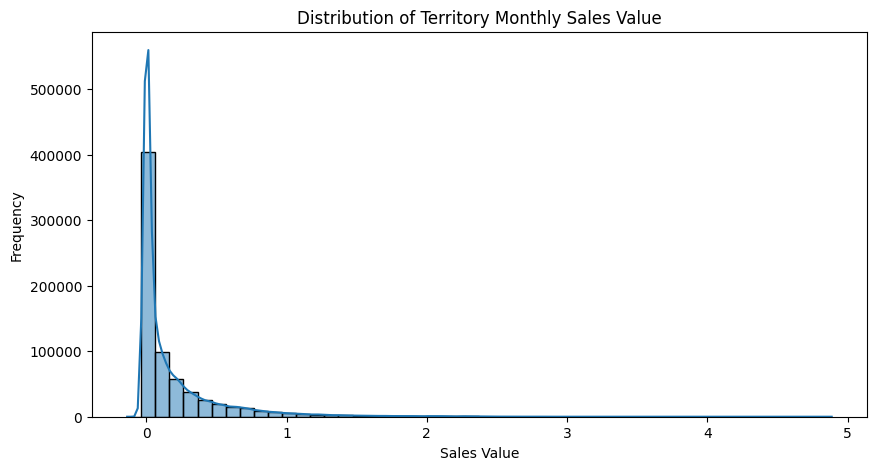

In [36]:
#A. Histogram
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_v_long,
    x='Sales_val',
    bins=50,
    kde=True
)

plt.title('Distribution of Territory Monthly Sales Value')
plt.xlabel('Sales Value')
plt.ylabel('Frequency')
plt.show()

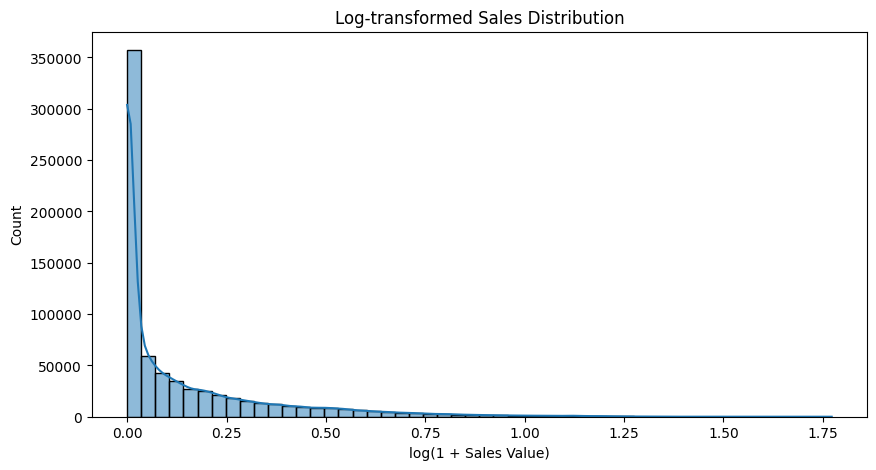

In [39]:
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(df_v_long['Sales_val'].clip(lower=0)),
    bins=50,
    kde=True
)

plt.title('Log-transformed Sales Distribution')
plt.xlabel('log(1 + Sales Value)')
plt.show()

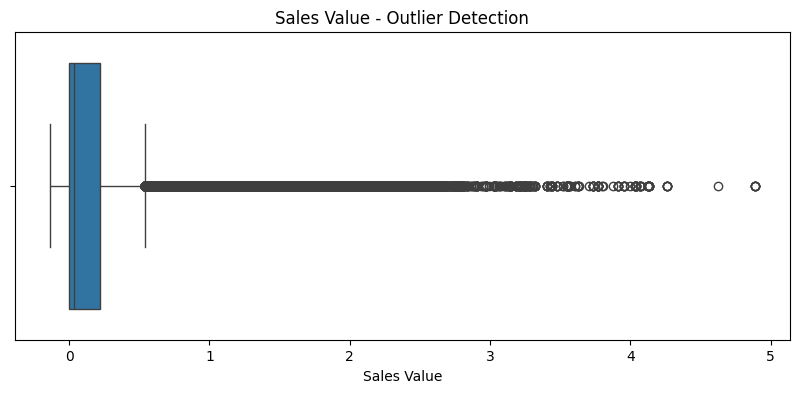

In [37]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df_v_long['Sales_val'])

plt.title('Sales Value - Outlier Detection')
plt.xlabel('Sales Value')
plt.show()

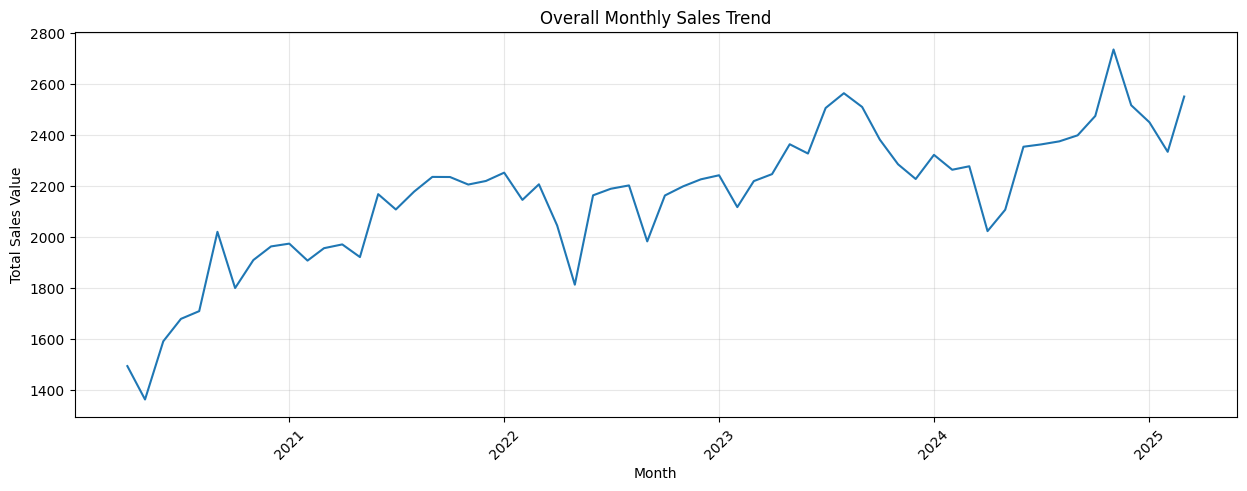

In [40]:
#Time-based EDA
monthly_sales = (
    df_v_long.groupby('Month')['Sales_val']
    .sum()
    .reset_index()
)

plt.figure(figsize=(15, 5))

sns.lineplot(
    data=monthly_sales,
    x='Month',
    y='Sales_val'
)

plt.title('Overall Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales Value')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

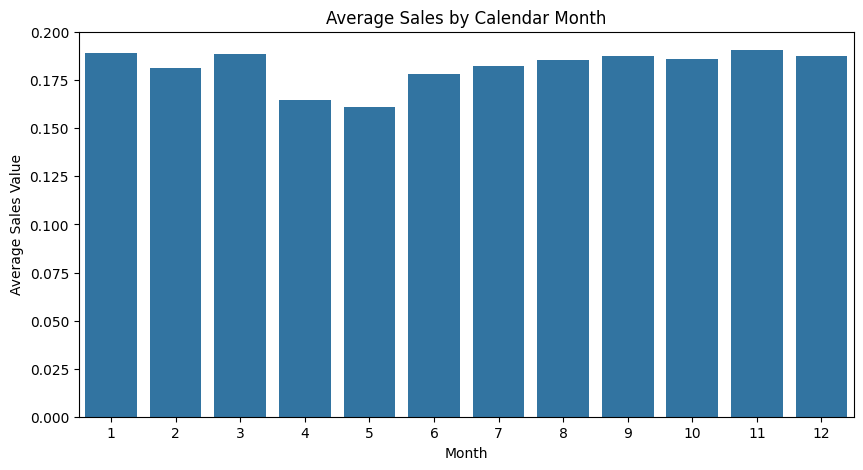

In [53]:
#Monthly seasonality
monthly_seasonality = (
    df_v_long.groupby('month')['Sales_val']
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly_seasonality,
    x='month',
    y='Sales_val'
)

plt.title('Average Sales by Calendar Month')
plt.xlabel('Month')
plt.ylabel('Average Sales Value')
plt.show()

In [57]:
df_v_long['month']

,month
0,4
1,4
2,4
3,4
4,4
...,...
713155,3
713156,3
713157,3
713158,3


,BRAND,Sales_val
0,URSOCOL,15112.290429
1,NEUGABA,9994.234029
2,OLMEZEST,7823.410716
3,SOMPRAZ,7813.026078
4,SYNDOPA,7191.400907
5,ENCORATE,6366.824160
6,MIRTAZ,6323.728934
7,RIVAMER,6266.950503
8,OLMEZEST AM,6160.440543
9,LEVIPIL,3719.975349


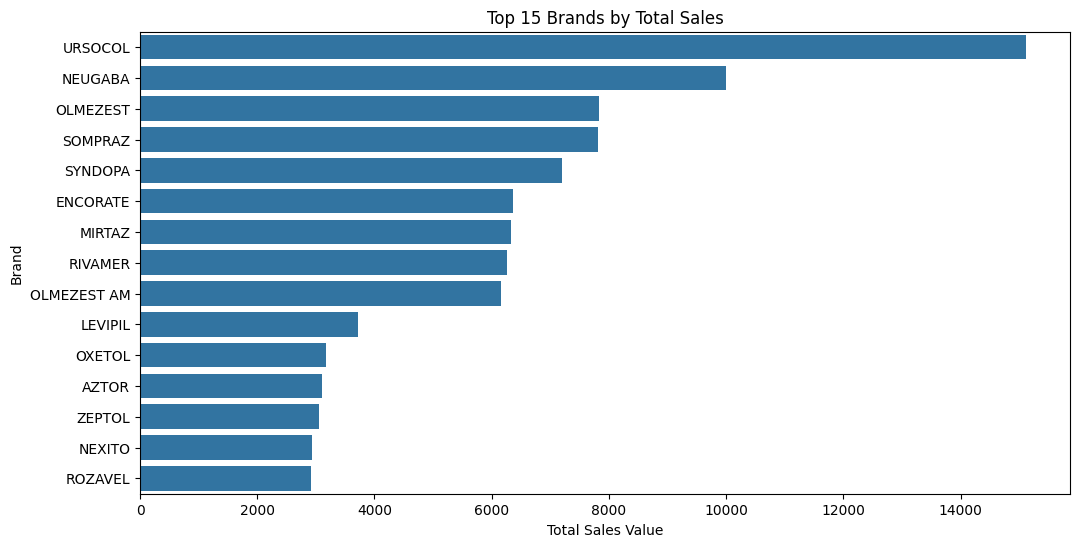

In [58]:
# Brand-wise sales analysis
brand_sales = (
    df_v_long.groupby('BRAND')['Sales_val']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(brand_sales.head(15))

plt.figure(figsize=(12, 6))

sns.barplot(
    data=brand_sales.head(15),
    x='Sales_val',
    y='BRAND'
)

plt.title('Top 15 Brands by Total Sales')
plt.xlabel('Total Sales Value')
plt.ylabel('Brand')
plt.show()

,DIVISION,Sales_val
0,SYNERGY,58068.858293
1,AVIOR-2,28701.741166
2,AVIOR,19371.394472
3,SOLARES,13499.707732
4,AZURA,10066.016006
5,ONCO,24.546029


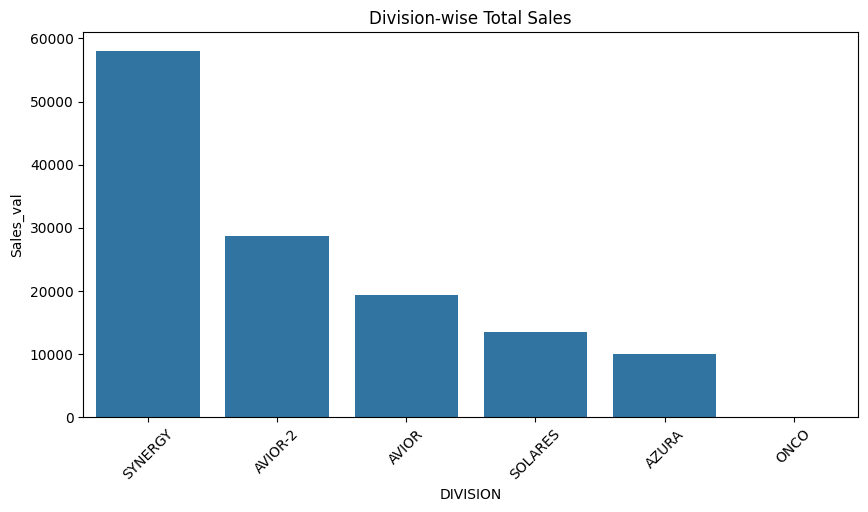

In [59]:
# Division wise sales
division_sales = (
    df_v_long.groupby('DIVISION')['Sales_val']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(division_sales)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=division_sales,
    x='DIVISION',
    y='Sales_val'
)

plt.title('Division-wise Total Sales')
plt.xticks(rotation=45)
plt.show()

,Therapy,Sales_val
0,NEURO,42866.392549
1,GASTRO,27709.947318
2,CARDIO,26207.259575
3,PSYCHIA,25196.699772
4,DIABETO,5580.832353
5,URO,680.354835
6,RESPIRA,579.576791
7,ORTHO,439.347964
8,ANTI VIRAL,335.450882
9,GYNAE,111.855630


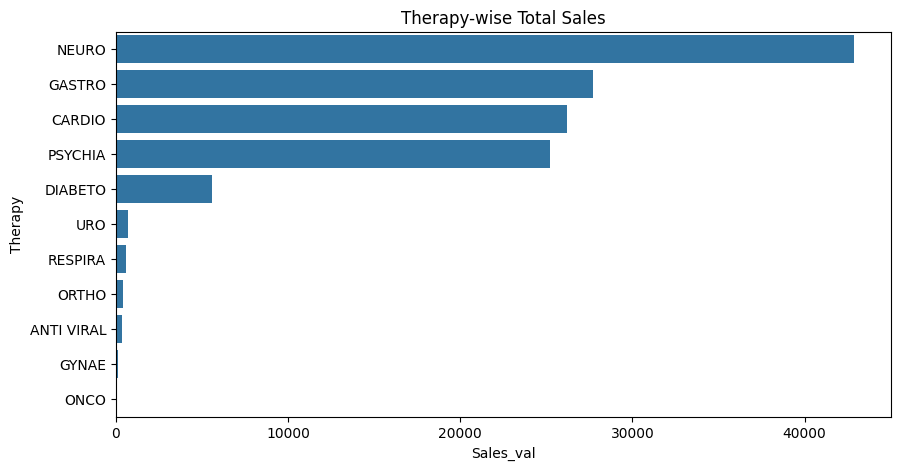

In [61]:
#Therapy-wise sales analysis
therapy_sales = (
    df_v_long.groupby('Therapy')['Sales_val']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(therapy_sales)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=therapy_sales,
    x='Sales_val',
    y='Therapy'
)

plt.title('Therapy-wise Total Sales')
plt.show()

In [62]:
#Territory-wise sales analysis
territory_sales = (
    df_v_long.groupby('HQ-Name')['Sales_val']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("Top 10 Territories")
display(territory_sales.head(10))

print("Bottom 10 Territories")
display(territory_sales.tail(10))

Top 10 Territories


,HQ-Name,Sales_val
0,DINAJPUR-SYNERGY,963.606335
1,NAOGAON-SYNERGY,838.197475
2,MOHIPAL-SYNERGY-FENI,790.953838
3,TRANK ROAD-SYNERGY-FENI,790.953838
4,KUSHTIA-SYNERGY,785.126183
5,SIGNBOARD-SYNERGY,779.396085
6,BOGURA-JOY-SYNERGY,759.357819
7,BOGURA-SYNERGY-SOUTH,759.357819
8,AMBORKHANA-SYNERGY-SYLHET,745.202521
9,MIRER MOYDAN-SYNERGY-SYLHET,745.202521


Bottom 10 Territories


,HQ-Name,Sales_val
385,SANTINAGAR-AZURA-DHAKA,115.761211
386,SANKAR-AZURA-DHAKA,115.761211
387,BASHIR UDDIN ROAD-AZURA-DHAKA,115.761211
388,BASUNDHARA-AZURA-DHAKA,115.761211
389,SHAJAHANPUR-AZURA-DHAKA,115.761211
390,BASHABO-AZURA-DHAKA,115.761211
391,UTTAR KHAN-AZURA-UTTARA,115.761211
392,ZIGATOLA-AZURA-DHAKA,115.761211
393,FLM-02,12.273015
394,FLM-01,12.273015


In [63]:
zero_sales = (
    df_v_long.groupby('BRAND')
    .agg(
        Total_Records=('Sales_val', 'count'),
        Zero_Sales=('Sales_val', lambda x: (x == 0).sum()),
        Total_Sales=('Sales_val', 'sum')
    )
)

zero_sales['Zero_Sales_Percentage'] = (
    zero_sales['Zero_Sales'] /
    zero_sales['Total_Records'] * 100
)

display(
    zero_sales.sort_values(
        'Zero_Sales_Percentage',
        ascending=False
    ).head(15)
)

,Total_Records,Zero_Sales,Total_Sales,Zero_Sales_Percentage
BRAND,,,,
IDROFOS KIT,13860,13856,-0.009680,99.971140
LOTENSYL,13260,13256,-0.000420,99.969834
ZOFER,13860,13855,-0.001240,99.963925
PANZER,13860,13853,-0.002710,99.949495
MONOTRATE,13260,13244,-0.009180,99.879336
EXZILOR,6360,6329,-0.014020,99.512579
ATOSIBAN SUN,13860,12820,49.659606,92.496392
NAXIPRAZ,13860,12730,53.983719,91.847042
RALECT,6360,5839,25.136526,91.808176


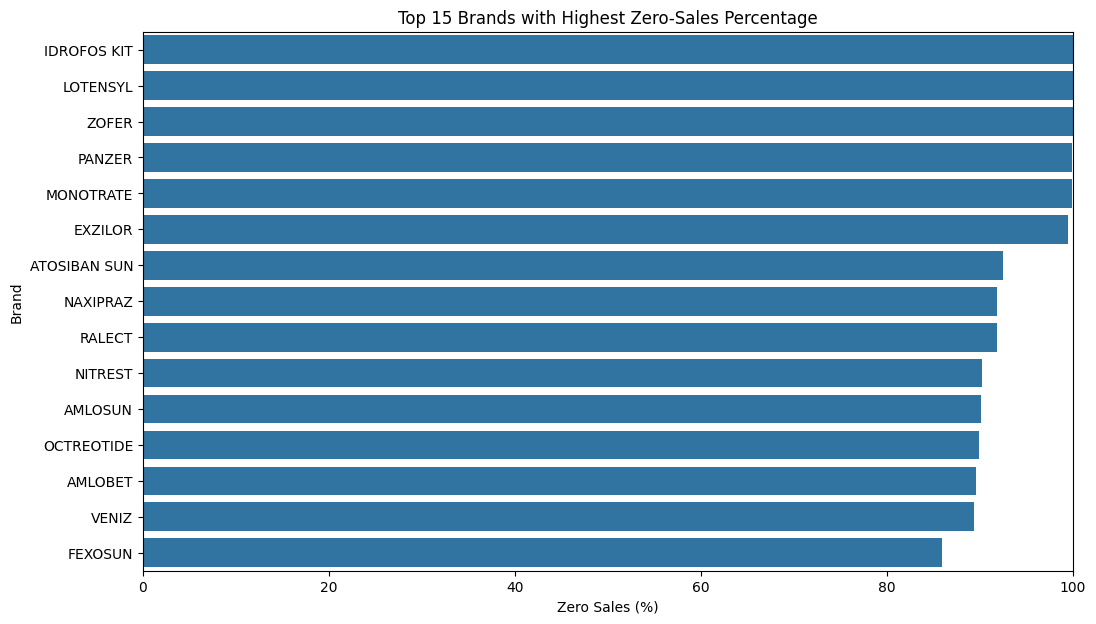

In [65]:
# Visualize brands with the highest zero-sales percentage
top_zero = (
    zero_sales
    .sort_values('Zero_Sales_Percentage', ascending=False)
    .head(15)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_zero,
    x='Zero_Sales_Percentage',
    y='BRAND'
)

plt.title('Top 15 Brands with Highest Zero-Sales Percentage')
plt.xlabel('Zero Sales (%)')
plt.ylabel('Brand')
plt.xlim(0, 100)
plt.show()

In [66]:
#Investigate whether these brands have sales in particular territories

brand_name = 'IDROFOS KIT'

brand_territory = (
    df_v_long[df_v_long['BRAND'] == brand_name]
    .groupby('HQ-Name')
    .agg(
        Total_Months=('Sales_val', 'count'),
        Zero_Months=('Sales_val', lambda x: (x == 0).sum()),
        Total_Sales=('Sales_val', 'sum')
    )
)

brand_territory['Non_Zero_Months'] = (
    brand_territory['Total_Months'] -
    brand_territory['Zero_Months']
)

display(
    brand_territory.sort_values(
        'Total_Sales',
        ascending=False
    ).head(20)
)

,Total_Months,Zero_Months,Total_Sales,Non_Zero_Months
HQ-Name,,,,
AKHALIA-SOLARES-SYLHET,60,60,0.0,0
AMIRABAD-CTG-AVIOR,60,60,0.0,0
ANJUMAN-E-KAKRAIL-SOLARES-DHAKA,60,60,0.0,0
ARJATPARA-MOHAKHLI-SOLARES-DHAKA,60,60,0.0,0
AZAMPUR UTTARA-SOLARES-DHAKA,60,60,0.0,0
BAGERHAT-AVIOR,60,60,0.0,0
BAGHMARA-SOLARES-MYMENSINGH,60,60,0.0,0
BANASREE-RAMPURA-SOLARES-DHAKA,60,60,0.0,0
BANDARTILA-SOLARES-CHITTAGONG,60,60,0.0,0


In [67]:
def get_fy(date):
    start_year = date.year - (date.month < 4)
    return f"{start_year}-{str(start_year + 1)[-2:]}"

df_v_long['FY'] = df_v_long['Month'].apply(get_fy)

In [68]:
#Calculate financial-year-wise sales
fy_sales = (
    df_v_long.groupby('FY')['Sales_val']
    .sum()
    .reset_index()
)

display(fy_sales)

,FY,Sales_val
0,2020-21,21374.129879
1,2021-22,25847.018474
2,2022-23,25562.542949
3,2023-24,28271.176849
4,2024-25,28677.395548


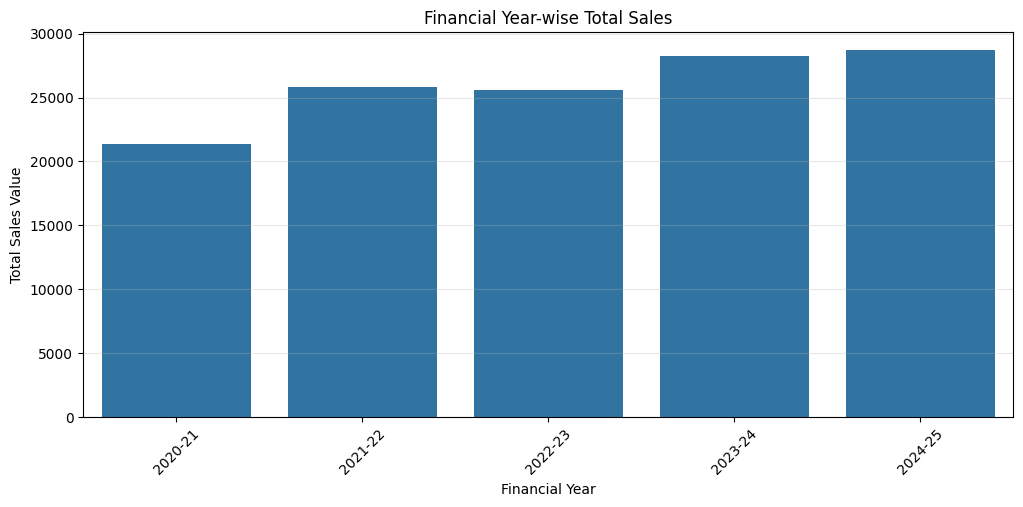

In [69]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=fy_sales,
    x='FY',
    y='Sales_val'
)

plt.title('Financial Year-wise Total Sales')
plt.xlabel('Financial Year')
plt.ylabel('Total Sales Value')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.show()

In [70]:
#Financial Year-over-Year growth
fy_sales['YoY_Growth_%'] = (
    fy_sales['Sales_val'].pct_change() * 100
)

display(fy_sales.round(2))

,FY,Sales_val,YoY_Growth_%
0,2020-21,21374.13,NaN
1,2021-22,25847.02,20.93
2,2022-23,25562.54,-1.10
3,2023-24,28271.18,10.60
4,2024-25,28677.40,1.44


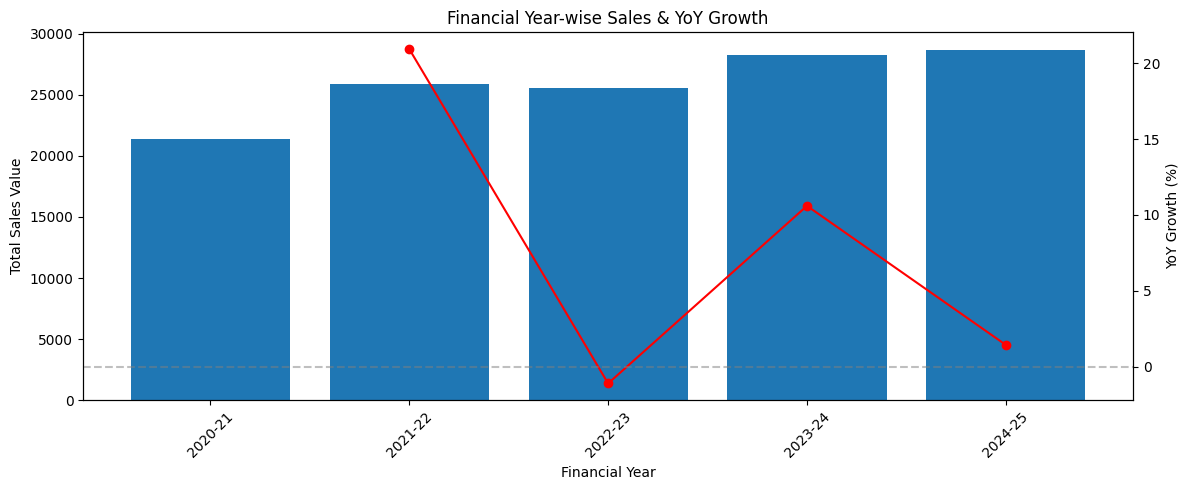

In [72]:
#FY sales + YoY growth
fig, ax1 = plt.subplots(figsize=(12, 5))

# 1. Financial year sales (Bar)
ax1.bar(fy_sales['FY'], fy_sales['Sales_val'], label='Sales')

ax1.set_xlabel('Financial Year')
ax1.set_ylabel('Total Sales Value')
ax1.set_title('Financial Year-wise Sales & YoY Growth')

# 2. YoY growth (Line)
ax2 = ax1.twinx()

ax2.plot(
    fy_sales['FY'],
    fy_sales['YoY_Growth_%'],
    marker='o',
    color='red',
    label='YoY Growth (%)'
)

ax2.set_ylabel('YoY Growth (%)')
ax2.axhline(0, color='gray', linestyle='--', alpha=0.5)

# 3. Formatting
ax1.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [71]:
#Division-wise financial year comparison
fy_division = (
    df_v_long.groupby(['FY', 'DIVISION'])['Sales_val']
    .sum()
    .reset_index()
)

fy_division_pivot = fy_division.pivot(
    index='DIVISION',
    columns='FY',
    values='Sales_val'
)

display(fy_division_pivot)

FY,2020-21,2021-22,2022-23,2023-24,2024-25
DIVISION,,,,,
AVIOR,3348.904241,3914.785323,3741.958047,4137.499807,4228.247054
AVIOR-2,4835.808640,5856.579563,5503.000971,6071.985010,6434.366981
AZURA,1698.133166,2104.294578,1884.552291,2187.864464,2191.171508
ONCO,0.000000,0.000000,0.000000,13.582300,10.963730
SOLARES,2167.195765,2857.815840,2730.251106,2842.775580,2901.669442
SYNERGY,9324.088066,11113.543170,11702.780534,13017.469689,12910.976833
